# Fetal Head Circumference: Measurement and Error Analysis

### Section 1: Setup

This is my part of the project. The two U-Nets already found the head in every validation and test image and saved the masks to our shared Drive folder. I take those masks, turn them into a head circumference (HC) in millimeters, and dig into where and why the number is off. Nothing gets trained here, so a regular CPU runtime is enough.

In [12]:
import os
import shutil
from concurrent.futures import ThreadPoolExecutor

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

plt.rcParams["figure.dpi"] = 70

In [13]:
# mount Google Drive (
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
DRIVE_DIR = "/content/drive/MyDrive/aai-521-hc18"   # shortcut to the shared folder
LOCAL_DIR = "/content/hc18"                          # copy on the Colab disk, much faster to read

MODELS = ["unet_plain", "unet_resnet34"]
NAMES = {"unet_plain": "Plain U-Net", "unet_resnet34": "ResNet-34 U-Net"}
TRAIN_SIZE = 256        # the models saw every image squashed to 256 x 256
SIZE_BINS = [0, 100, 200, 400]
SIZE_LABELS = ["under 100 mm", "100 to 200 mm", "over 200 mm"]

RESULT_DIR = os.path.join(DRIVE_DIR, "results")
FIG_DIR = os.path.join(DRIVE_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

#### Copy the files I need to the Colab disk

Reading straight from Drive is slow the first time. I only need the validation and test images since those are the only ones with predicted masks. For each one that is the ultrasound, the doctors' outline, the filled mask, and one predicted mask per model. I copy them 16 at a time.

In [16]:
splits = pd.read_csv(os.path.join(DRIVE_DIR, "splits.csv"))
df = splits[splits["split"].isin(["val", "test"])].reset_index(drop=True)

files = []
for name in df["filename"]:
    outline = name.replace(".png", "_Annotation.png")
    files.append(os.path.join("raw", "training_set", name))
    files.append(os.path.join("raw", "training_set", outline))
    files.append(os.path.join("masks", name))
    for m in MODELS:
        files.append(os.path.join("results", "pred_masks", m, name))


def copy_file(rel_path):
    dst = os.path.join(LOCAL_DIR, rel_path)
    if not os.path.exists(dst):
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        shutil.copyfile(os.path.join(DRIVE_DIR, rel_path), dst)


with ThreadPoolExecutor(max_workers=16) as pool:
    list(pool.map(copy_file, files))

print("Files copied:", len(files))
print(df["split"].value_counts())

Files copied: 1495
split
val     150
test    149
Name: count, dtype: int64


### Section 2: Measuring the Predicted Masks

I measure the same way the earlier notebooks did so my numbers line up with theirs. Take the outer edge of the biggest blob, drop any edge points sitting on the image border (a head cut off by the frame has a straight edge there that is not skull), fit an ellipse with OpenCV, and get its perimeter with Ramanujan's formula.

The one thing I do differently is keep the circumference in pixels first and only then multiply by the pixel size. Having both lets me tell apart a mask that is actually wrong from one that only looks bad because each pixel covers a lot of millimeters.

I also rebuild two image quality numbers for every image. Skull contrast is how much brighter the doctors' outline is than the image overall, so low means a faint skull. Cut off means the head touches the edge of the frame.

In [17]:
def ellipse_perimeter(a, b):
    # Ramanujan's approximation, a and b are the two semi axes
    h = ((a - b) / (a + b)) ** 2
    return np.pi * (a + b) * (1 + 3 * h / (10 + np.sqrt(4 - 3 * h)))


def hc_pixels(mask):
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    if not contours:
        return np.nan
    pts = max(contours, key=cv2.contourArea).reshape(-1, 2)

    # skip points on the image border
    h, w = mask.shape
    keep = (pts[:, 0] > 0) & (pts[:, 0] < w - 1) & (pts[:, 1] > 0) & (pts[:, 1] < h - 1)
    pts = pts[keep]
    if len(pts) < 5:   # fitEllipse needs 5 points at least
        return np.nan

    _, axes, _ = cv2.fitEllipse(pts)
    return ellipse_perimeter(axes[0] / 2, axes[1] / 2)


def load_mask(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    return (img > 127).astype(np.uint8)


def dice(pred, truth):
    total = pred.sum() + truth.sum()
    if total == 0:
        return 1.0
    return 2 * (pred * truth).sum() / total


def skull_contrast(img, outline):
    band = cv2.dilate(outline, np.ones((5, 5), np.uint8)) > 127
    return img[band].mean() - img.mean()


def is_cut_off(mask):
    return bool(mask[0].any() or mask[-1].any() or mask[:, 0].any() or mask[:, -1].any())

In [18]:
img_dir = os.path.join(LOCAL_DIR, "raw", "training_set")
mask_dir = os.path.join(LOCAL_DIR, "masks")
pred_dir = os.path.join(LOCAL_DIR, "results", "pred_masks")

rows = []
for r in df.itertuples():
    img = cv2.imread(os.path.join(img_dir, r.filename), cv2.IMREAD_GRAYSCALE)
    outline = cv2.imread(os.path.join(img_dir, r.filename.replace(".png", "_Annotation.png")),
                         cv2.IMREAD_GRAYSCALE)
    truth = load_mask(os.path.join(mask_dir, r.filename))

    row = {
        "filename": r.filename,
        "split": r.split,
        "pixel_mm": r.pixel_size_mm,
        "true_hc": r.true_hc_mm,
        "width_px": img.shape[1],
        "contrast": skull_contrast(img, outline),
        "cut_off": is_cut_off(truth),
    }
    for m in MODELS:
        pred = load_mask(os.path.join(pred_dir, m, r.filename))
        row[m + "_hc"] = hc_pixels(pred) * r.pixel_size_mm
        row[m + "_dice"] = dice(pred, truth)
    rows.append(row)

results = pd.DataFrame(rows)
results["size_group"] = pd.cut(results["true_hc"], bins=SIZE_BINS, labels=SIZE_LABELS)
for m in MODELS:
    results[m + "_err"] = results[m + "_hc"] - results["true_hc"]
    results[m + "_err_px"] = results[m + "_err"] / results["pixel_mm"]

results.head()

,filename,split,pixel_mm,true_hc,width_px,contrast,cut_off,unet_plain_hc,unet_plain_dice,unet_resnet34_hc,unet_resnet34_dice,size_group,unet_plain_err,unet_plain_err_px,unet_resnet34_err,unet_resnet34_err_px
0,001_HC.png,test,0.089659,56.81,800,23.470237,False,56.494984,0.947537,54.985695,0.934876,under 100 mm,-0.315016,-3.513509,-1.824305,-20.347260
1,004_HC.png,val,0.061240,59.81,800,21.203427,False,60.681154,0.974000,59.146822,0.970212,under 100 mm,0.871154,14.225276,-0.663178,-10.829198
2,005_HC.png,test,0.115814,69.80,800,7.296900,False,76.401765,0.919154,73.460181,0.959600,under 100 mm,6.601765,57.003189,3.660181,31.603976
3,010_2HC.png,test,0.079927,72.87,800,15.747046,False,76.752331,0.945024,72.667284,0.967506,under 100 mm,3.882331,48.573312,-0.202716,-2.536251
4,010_HC.png,test,0.079935,71.91,800,19.369749,False,73.226513,0.962247,73.842181,0.975034,under 100 mm,1.316513,16.469764,1.932181,24.171847


#### Check against the model notebooks

Before going further I make sure my test numbers match the per image tables the model notebooks saved. The gap should be basically zero. If it is not, the masks in Drive are not the ones that were scored.

In [19]:
for m in MODELS:
    saved = pd.read_csv(os.path.join(RESULT_DIR, m + "_test_per_image.csv"))
    both = results.merge(saved[["filename", "pred_hc_mm"]], on="filename")
    gap = (both[m + "_hc"] - both["pred_hc_mm"]).abs().max()
    print(NAMES[m])
    print("  test images matched:", len(both))
    print("  biggest gap (mm):", round(gap, 4))
    print("  failed ellipse fits:", results[m + "_hc"].isna().sum())

Plain U-Net
  test images matched: 149
  biggest gap (mm): 0.0
  failed ellipse fits: 0
ResNet-34 U-Net
  test images matched: 149
  biggest gap (mm): 0.0
  failed ellipse fits: 0


#### What the check showed

Both models match the model notebooks exactly. All 149 test images lined up with a gap of 0.0 mm, and not one ellipse fit failed. So everything below is measured on the same masks that were scored, and any change in the numbers comes from what I do with the measurements, not from measuring differently.

### Section 3: Fixing the Overestimate

Both models read high on average, and I already know why. The doctors draw the outline as a line a few pixels thick and our filled masks include that line, so even the doctors' own masks come out about 0.7 mm bigger than the doctors' numbers. The models learned from those masks and picked up the same habit.

I try two fixes:

1. Subtract one fixed amount in mm from every prediction.
2. Subtract one fixed amount in pixels, then convert it to mm with each image's own pixel size.

My bet is on the second. The drawn line is about the same thickness in pixels on every scan, so the extra length it adds is fixed in pixels and grows in mm as the pixel size grows. A single mm amount would overcorrect zoomed in scans and undercorrect zoomed out ones.

The amounts come from the validation images only. I keep whichever fix does better on validation and then score the test images once with it. The test set never gets a vote, which is the same rule the model notebooks followed.

In [20]:
val = results[results["split"] == "val"].copy()
test = results[results["split"] == "test"].copy()

fix_table = []
best_fix = {}
for m in MODELS:
    mm_offset = val[m + "_err"].mean()
    px_offset = val[m + "_err_px"].mean()

    options = {
        "no fix": val[m + "_err"],
        "fixed mm": val[m + "_err"] - mm_offset,
        "fixed pixels": val[m + "_err"] - px_offset * val["pixel_mm"],
    }
    for fix, err in options.items():
        fix_table.append({"model": NAMES[m], "fix": fix,
                          "val MAE (mm)": err.abs().mean(),
                          "val mean error (mm)": err.mean()})

    # pick the better fix on validation, then apply it to val and test
    best = min(["fixed mm", "fixed pixels"], key=lambda f: options[f].abs().mean())
    best_fix[m] = best
    for part in (val, test):
        if best == "fixed mm":
            part[m + "_fixed"] = part[m + "_err"] - mm_offset
        else:
            part[m + "_fixed"] = part[m + "_err"] - px_offset * part["pixel_mm"]

    print(NAMES[m], "| offset:", round(mm_offset, 2), "mm or", round(px_offset, 2),
          "px | picked:", best)

print()
print(pd.DataFrame(fix_table).round(3).to_string(index=False))

Plain U-Net | offset: 1.08 mm or 7.19 px | picked: fixed pixels
ResNet-34 U-Net | offset: 0.43 mm or 3.27 px | picked: fixed pixels

          model          fix  val MAE (mm)  val mean error (mm)
    Plain U-Net       no fix         2.063                1.080
    Plain U-Net     fixed mm         1.842               -0.000
    Plain U-Net fixed pixels         1.790                0.064
ResNet-34 U-Net       no fix         1.830                0.425
ResNet-34 U-Net     fixed mm         1.768               -0.000
ResNet-34 U-Net fixed pixels         1.746               -0.036


In [21]:
# test set, scored once
test_table = []
for m in MODELS:
    for when, col in [("before", m + "_err"), ("after", m + "_fixed")]:
        test_table.append({"model": NAMES[m], "fix": when,
                           "test MAE (mm)": test[col].abs().mean(),
                           "test mean error (mm)": test[col].mean(),
                           "test median abs (mm)": test[col].abs().median()})

test_table = pd.DataFrame(test_table)
test_table.to_csv(os.path.join(RESULT_DIR, "measurement_fix_test.csv"), index=False)
print(test_table.round(3).to_string(index=False))

          model    fix  test MAE (mm)  test mean error (mm)  test median abs (mm)
    Plain U-Net before          2.315                 1.215                 1.589
    Plain U-Net  after          2.060                 0.221                 1.429
ResNet-34 U-Net before          2.049                 0.647                 1.687
ResNet-34 U-Net  after          1.972                 0.196                 1.671


#### What the fix did

The pixel fix won on validation for both models, which backs up the line thickness explanation. On the test set the plain U-Net dropped from 2.315 to 2.060 mm MAE and its average lean went from +1.215 mm to +0.221 mm. The ResNet-34 U-Net moved less, 2.049 to 1.972 mm, because it was only leaning +0.647 mm to begin with.

The size of each lean says something too. The filled masks alone carry about 0.7 mm. The plain U-Net leaned more than that (+1.08 mm on validation), and it is also the one that picked a 0.4 threshold instead of 0.5, so it calls more edge pixels head and its masks come out a little fat. The ResNet-34 U-Net leaned less than the masks it learned from (+0.43 mm), so it already draws a slightly tighter outline.

The biggest takeaway is how much of the gap between the two models was just this lean. Before the fix the pretrained model was 0.267 mm better. After it, the gap is 0.088 mm. About two thirds of what the pretrained encoder seemed to buy us comes from a one line correction the plain model can use too.

What the fix does not touch is the spread. The ResNet-34 median barely moved (1.687 to 1.671 mm). It removes the lean, it does not make the misses smaller.

### Section 4: Combining Both Models

The two models do not always miss on the same images. If one reads a little high where the other reads a little low, averaging their two measurements should cancel some of that out. This costs nothing since both sets of masks already exist. Averaging separate models is one of the oldest ways to get a steadier answer (Dietterich, 2000).

I compare the ResNet-34 U-Net alone against the average of both, after each one's fix. Same rule as before: validation decides, test gets scored once.

In [22]:
for part in (val, test):
    part["avg_fixed"] = (part["unet_plain_fixed"] + part["unet_resnet34_fixed"]) / 2

# how often the two models miss in opposite directions
opposite = (np.sign(val["unet_plain_fixed"]) != np.sign(val["unet_resnet34_fixed"])).mean()
print("Val images where the two models miss in opposite directions:", f"{opposite:.0%}")

choices = {"ResNet-34 U-Net": "unet_resnet34_fixed", "average of both": "avg_fixed"}
for label, col in choices.items():
    print(label, "| val MAE:", round(val[col].abs().mean(), 3), "mm")

final_label = min(choices, key=lambda k: val[choices[k]].abs().mean())
final_col = choices[final_label]
print()
print("Final measurement:", final_label)
print("Test MAE:", round(test[final_col].abs().mean(), 3), "mm")
print("Test mean error:", round(test[final_col].mean(), 3), "mm")

Val images where the two models miss in opposite directions: 21%
ResNet-34 U-Net | val MAE: 1.746 mm
average of both | val MAE: 1.678 mm

Final measurement: average of both
Test MAE: 1.942 mm
Test mean error: 0.208 mm


#### What combining did

Averaging won on validation (1.678 vs 1.746 mm), so it is the final measurement. On the test set it lands at 1.942 mm MAE with an average lean of +0.208 mm. That is 0.107 mm better than the ResNet-34 U-Net straight out of its notebook, and 0.373 mm (16%) better than the plain U-Net we started with.

The gain over the fixed ResNet-34 alone is small, 0.03 mm, and the reason is right in the first number. The two models miss in opposite directions on only 21% of the validation images. The other 79% of the time they miss the same way, and averaging two numbers that are both too high still gives a number that is too high. The worst images in Section 6 show this clearly.

### Section 5: Why Large Heads Miss More

The model notebooks showed the error is highest on heads over 200 mm. My guess is pixel size. The models only ever see a 256 x 256 copy of each scan, so on an 800 pixel wide image one model pixel covers about 3 real pixels across. Large heads are late pregnancy scans that are zoomed out, so every pixel is worth more millimeters. The same small slip at the edge costs more mm on a big head even if the model is just as good there.

If that is the whole story, the error in pixels should be about the same for every head size and only the error in mm should grow. The table checks that. Below it, a rank correlation shows which property of the image tracks the final error the most. Near 0 means no link and near 1 means a strong one.

In [23]:
size_table = []
for m in MODELS:
    for group, part in test.groupby("size_group", observed=True):
        size_table.append({
            "model": NAMES[m],
            "head size": group,
            "images": len(part),
            "pixel size (mm)": part["pixel_mm"].mean(),
            "mm per model pixel": (part["pixel_mm"] * part["width_px"] / TRAIN_SIZE).mean(),
            "MAE (mm)": part[m + "_fixed"].abs().mean(),
            "MAE (px)": (part[m + "_fixed"] / part["pixel_mm"]).abs().mean(),
            "Dice": part[m + "_dice"].mean(),
        })

size_table = pd.DataFrame(size_table)
size_table.to_csv(os.path.join(RESULT_DIR, "measurement_error_by_size.csv"), index=False)
print(size_table.round(3).to_string(index=False))

          model     head size  images  pixel size (mm)  mm per model pixel  MAE (mm)  MAE (px)  Dice
    Plain U-Net  under 100 mm      28            0.086               0.269     1.884    22.531 0.952
    Plain U-Net 100 to 200 mm      89            0.134               0.418     1.707    12.234 0.980
    Plain U-Net   over 200 mm      32            0.197               0.614     3.198    16.743 0.978
ResNet-34 U-Net  under 100 mm      28            0.086               0.269     1.624    19.294 0.964
ResNet-34 U-Net 100 to 200 mm      89            0.134               0.418     1.725    13.005 0.981
ResNet-34 U-Net   over 200 mm      32            0.197               0.614     2.964    15.619 0.979


          factor  rho vs error (mm)  rho vs error (px)
      pixel size              0.219             -0.079
       head size              0.205             -0.047
  skull contrast              0.004             -0.044
Dice (ResNet-34)             -0.348             -0.431


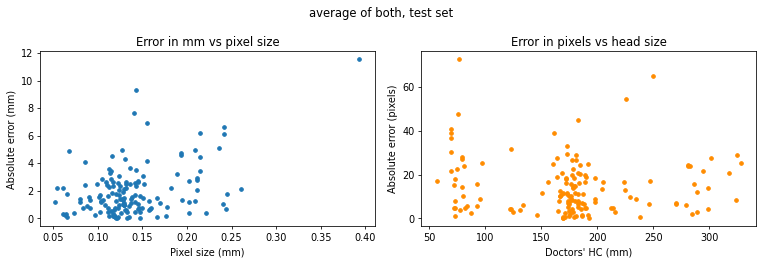

In [24]:
err_mm = test[final_col].abs()
err_px = err_mm / test["pixel_mm"]

factors = {
    "pixel size": test["pixel_mm"],
    "head size": test["true_hc"],
    "skull contrast": test["contrast"],
    "Dice (ResNet-34)": test["unet_resnet34_dice"],
}
corr = []
for name, values in factors.items():
    corr.append({"factor": name,
                 "rho vs error (mm)": spearmanr(values, err_mm).statistic,
                 "rho vs error (px)": spearmanr(values, err_px).statistic})
print(pd.DataFrame(corr).round(3).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].scatter(test["pixel_mm"], err_mm, s=14)
ax[0].set_xlabel("Pixel size (mm)")
ax[0].set_ylabel("Absolute error (mm)")
ax[0].set_title("Error in mm vs pixel size")
ax[1].scatter(test["true_hc"], err_px, s=14, color="darkorange")
ax[1].set_xlabel("Doctors' HC (mm)")
ax[1].set_ylabel("Absolute error (pixels)")
ax[1].set_title("Error in pixels vs head size")
fig.suptitle(final_label + ", test set")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "measurement_error_vs_pixel_size.png"), dpi=150)
plt.show()

#### What the size breakdown showed

Pixel size explains why large heads look worse, but they are not where the models struggle most.

In millimeters the over 200 mm heads are clearly the worst, 2.96 mm for the ResNet-34 U-Net against 1.73 mm for the middle group, about 70% higher. Each model pixel on those scans is worth 0.614 mm, more than double the 0.269 mm on the small heads. In pixels the same big heads miss by 15.6 against 13.0, only 20% higher. The correlations say the same thing. Pixel size has a link of 0.219 with the error in mm and basically none in pixels (-0.079). Head size behaves the same way.

The real shape trouble is on small heads. They have the largest pixel error of any group (19.3 px for ResNet-34 and 22.5 px for the plain model) and the lowest Dice (0.964 and 0.952). That gets hidden in mm because their pixels are so small. Early scans are harder for both models, the tiny pixel size just covers it up.

Skull contrast has no link at all (0.004), which surprised me since faint skulls cluster in the small heads. Faintness alone is not what drives the error. Dice is the strongest link (-0.348 in mm, -0.431 in px), which makes sense: when the measurement is far off, the outline itself is off.

The single dot far right in the left plot is 637_HC.png, the image with the largest pixel size in the whole dataset (0.393 mm). It shows up again in Section 6.

### Section 6: The Worst Test Images

These are the 10 test images with the biggest error after the fix. Green is the doctors' mask, red is the ResNet-34 U-Net and dotted blue is the plain U-Net. The table shows the things that could explain each miss. A high Dice with a big mm error means the outline was close but each pixel was worth a lot. A low Dice means the model got the shape itself wrong.

   filename  true_hc  avg_fixed  pixel_mm  contrast  cut_off  unet_resnet34_dice
 637_HC.png   172.69     11.544     0.393   114.421    False               0.955
 687_HC.png   249.50     -9.287     0.143    56.134    False               0.963
 654_HC.png   225.80     -7.670     0.141    59.580    False               0.964
583_2HC.png   182.99      6.928     0.155    83.926    False               0.962
 778_HC.png   301.30      6.666     0.241    71.873    False               0.976
768_2HC.png   324.61     -6.168     0.214    40.733    False               0.981
 784_HC.png   328.00     -6.154     0.241    21.930    False               0.981
 752_HC.png   294.12     -5.141     0.236    65.659    False               0.961
 375_HC.png   161.36      4.992     0.127    96.577    False               0.968
 756_HC.png   283.00     -4.985     0.209    39.691    False               0.978


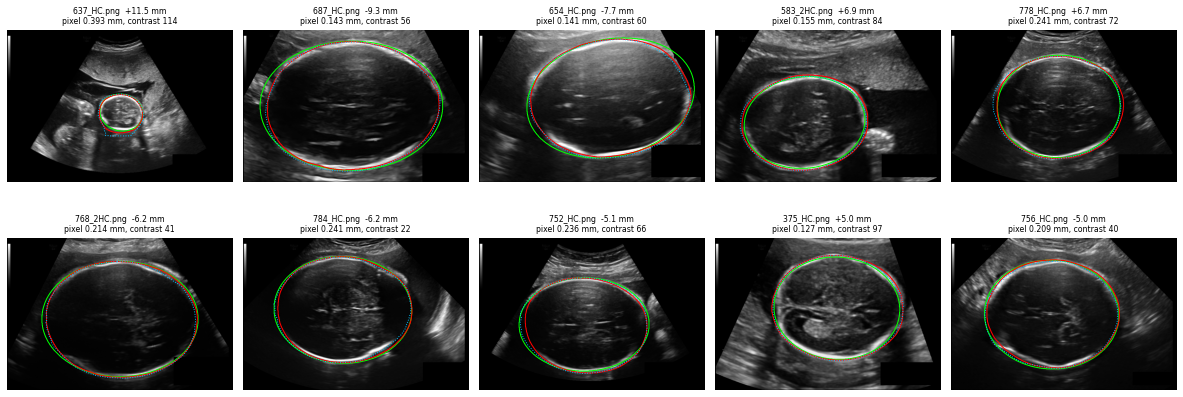

In [25]:
worst = test.loc[test[final_col].abs().sort_values(ascending=False).index[:10]]
print(worst[["filename", "true_hc", final_col, "pixel_mm", "contrast",
             "cut_off", "unet_resnet34_dice"]].round(3).to_string(index=False))

fig, axes = plt.subplots(2, 5, figsize=(17, 6.5))
for ax, r in zip(axes.ravel(), worst.itertuples()):
    img = cv2.imread(os.path.join(img_dir, r.filename), cv2.IMREAD_GRAYSCALE)
    ax.imshow(img, cmap="gray")
    ax.contour(load_mask(os.path.join(mask_dir, r.filename)), levels=[0.5],
               colors="lime", linewidths=1)
    ax.contour(load_mask(os.path.join(pred_dir, "unet_resnet34", r.filename)),
               levels=[0.5], colors="red", linewidths=1)
    ax.contour(load_mask(os.path.join(pred_dir, "unet_plain", r.filename)),
               levels=[0.5], colors="deepskyblue", linewidths=1, linestyles="dotted")
    err = getattr(r, final_col)
    ax.set_title(f"{r.filename}  {err:+.1f} mm\npixel {r.pixel_mm:.3f} mm, contrast {r.contrast:.0f}",
                 fontsize=8)
    ax.axis("off")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "measurement_worst_10.png"), dpi=150)
plt.show()

#### What the worst images showed

Seven of the ten are heads over 200 mm and none of them are cut off by the frame. Every Dice is between 0.955 and 0.981, so none of these are bad outlines. They are good outlines that slipped a few pixels on scans where each pixel is worth a lot.

Six of the seven big heads read low. Looking at 687_HC.png and 654_HC.png, the doctors' ellipse (green) sits outside the bright skull on one side while both models hug the bone. That is less a model failure and more a disagreement about where the edge is. Those two images alone cost 9.3 and 7.7 mm.

637_HC.png is the worst at +11.5 mm. It is a small head in a very zoomed out frame, with the largest pixel size in the dataset, so 11.5 mm is only about 29 pixels. Notebook 01 also flagged this image as the one where the doctors' own filled mask was furthest from their number (2.0 mm), so it was a hard image from the start.

Faint skulls are not the common thread. 784_HC.png is faint (contrast 22), but 637, 375 and 583_2 are some of the brightest in the set (114, 97, 84).

In every panel the red and dotted blue lines nearly sit on top of each other. Both models make the same mistake on the same image, which is exactly why averaging them barely helped here.

### Section 7: Agreement With the Doctors

An average error hides how far off the bad cases get. In medicine the usual way to compare a new measuring method against the current one is a Bland-Altman plot (Bland & Altman, 1986). Each dot is one test image. The x axis is the average of my number and the doctors' number, and the y axis is my number minus theirs. The middle line is the bias and the two outer lines are the 95% limits of agreement, which is the bias plus or minus 1.96 standard deviations. About 95 out of 100 new scans should land between them.

Bias: 0.21 mm
95% limits of agreement: -5.03 to 5.45 mm
Within 2 mm of the doctors: 62%
Within 5 mm of the doctors: 95%


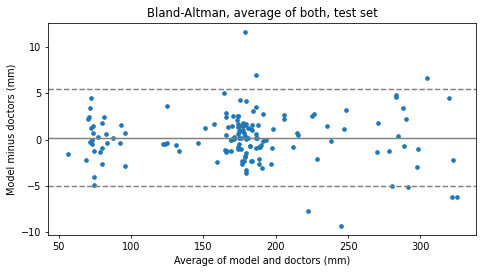

In [26]:
diff = test[final_col]
pred_hc = test["true_hc"] + diff
avg_hc = (pred_hc + test["true_hc"]) / 2

bias = diff.mean()
low = bias - 1.96 * diff.std()
high = bias + 1.96 * diff.std()

print("Bias:", round(bias, 2), "mm")
print("95% limits of agreement:", round(low, 2), "to", round(high, 2), "mm")
print("Within 2 mm of the doctors:", f"{(diff.abs() <= 2).mean():.0%}")
print("Within 5 mm of the doctors:", f"{(diff.abs() <= 5).mean():.0%}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(avg_hc, diff, s=14)
ax.axhline(bias, color="gray")
ax.axhline(low, color="gray", linestyle="--")
ax.axhline(high, color="gray", linestyle="--")
ax.set_xlabel("Average of model and doctors (mm)")
ax.set_ylabel("Model minus doctors (mm)")
ax.set_title("Bland-Altman, " + final_label + ", test set")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "measurement_bland_altman.png"), dpi=150)
plt.show()

#### What the agreement plot showed

The bias is +0.21 mm, so the fix did its job and there is almost no lean left. The 95% limits of agreement run from -5.03 to +5.45 mm, which means for a new scan I would expect the model to land within about 5 mm of the doctors 95 times out of 100. The test set agrees: 95% of images are within 5 mm and 62% within 2 mm.

The spread is not even across sizes. The middle cluster around 170 to 190 mm sits mostly within ±3 mm. Out past 250 mm the dots fan out to ±6 mm and beyond, which is the pixel size effect from Section 5 again. The limits are wide mostly because of the late pregnancy scans.

### Section 8: What the Error Means in Days

A couple of millimeters sounds tiny, but doctors do not use HC for its own sake. They use it to estimate how far along the pregnancy is. So I turn each measurement into gestational age with Hadlock's HC formula (Hadlock et al., 1984), where HC is in centimeters:

weeks = 8.96 + 0.540 x HC + 0.0003 x HC³

Then I compare the age from my HC to the age from the doctors' HC and report the gap in days. The formula is built for the second and third trimester, so I only use heads of 100 mm and up (about 15 weeks and later). The curve also bends, which means the same mm error is worth a different number of days depending on the stage, so I look at it by head size too.

In [27]:
def hadlock_weeks(hc_mm):
    hc_cm = hc_mm / 10
    return 8.96 + 0.540 * hc_cm + 0.0003 * hc_cm ** 3


ga = test[test["true_hc"] >= 100].copy()
ga["true_weeks"] = hadlock_weeks(ga["true_hc"])
ga["pred_weeks"] = hadlock_weeks(ga["true_hc"] + ga[final_col])
ga["days_off"] = (ga["pred_weeks"] - ga["true_weeks"]) * 7

print("Test images used:", len(ga))
print("Mean days off (absolute):", round(ga["days_off"].abs().mean(), 2))
print("Median days off (absolute):", round(ga["days_off"].abs().median(), 2))
print("Worst case:", round(ga["days_off"].abs().max(), 2), "days")
print("Within 1 day:", f"{(ga['days_off'].abs() <= 1).mean():.0%}")
print()

# how many days 1 mm is worth at different stages
for hc in [100, 150, 200, 250, 300]:
    per_mm = (hadlock_weeks(hc + 1) - hadlock_weeks(hc)) * 7
    print(f"1 mm at HC {hc} mm = {per_mm:.2f} days")
print()
print(ga.groupby("size_group", observed=True)["days_off"]
        .agg(lambda d: d.abs().mean()).round(2).rename("mean days off"))

Test images used: 121
Mean days off (absolute): 1.38
Median days off (absolute): 0.91
Worst case: 7.02 days
Within 1 day: 55%

1 mm at HC 100 mm = 0.44 days
1 mm at HC 150 mm = 0.52 days
1 mm at HC 200 mm = 0.63 days
1 mm at HC 250 mm = 0.77 days
1 mm at HC 300 mm = 0.95 days

size_group
100 to 200 mm    0.94
over 200 mm      2.59
Name: mean days off, dtype: float64


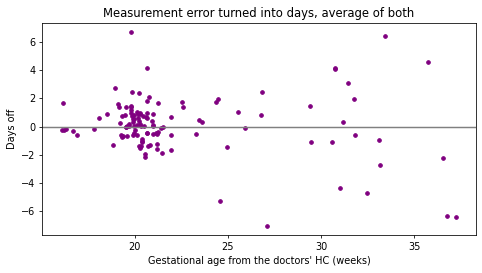

In [28]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(ga["true_weeks"], ga["days_off"], s=14, color="purple")
ax.axhline(0, color="gray")
ax.set_xlabel("Gestational age from the doctors' HC (weeks)")
ax.set_ylabel("Days off")
ax.set_title("Measurement error turned into days, " + final_label)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "measurement_days_off.png"), dpi=150)
plt.show()

#### What the days showed

On the 121 test heads of 100 mm and up, the model is off by 1.38 days on average and 0.91 days at the median. 55% are within one day and the worst is 7.02 days, which is the 687_HC.png head from Section 6 at about 27 weeks.

The days numbers show the late pregnancy problem is worse than the mm numbers suggest. One mm is worth 0.44 days at a 100 mm head and 0.95 days at 300 mm. The over 200 mm group already misses by more millimeters, and each of those millimeters is worth more days, so the two stack: 2.59 days against 0.94 days for the middle group, almost three times worse.

The plot shows it plainly. Around 20 weeks, where most of the test scans are, almost everything is within 2 days. Past 30 weeks the misses spread out to around ±6 days. If this were used in a clinic, the late scans are where a doctor should still check the number.

### Section 9: Saving the Results

The per image table and the summary numbers go into the results folder in our shared Drive, next to the model notebooks' files, so we can pull them straight into the report.

In [29]:
test.to_csv(os.path.join(RESULT_DIR, "measurement_test_per_image.csv"), index=False)

summary = pd.Series({
    "final measurement": final_label,
    "fix (ResNet-34)": best_fix["unet_resnet34"],
    "fix (plain)": best_fix["unet_plain"],
    "test MAE (mm)": round(diff.abs().mean(), 3),
    "bias (mm)": round(bias, 3),
    "limits of agreement (mm)": f"{low:.2f} to {high:.2f}",
    "mean days off": round(ga["days_off"].abs().mean(), 2),
})
summary.to_csv(os.path.join(RESULT_DIR, "measurement_summary.csv"), header=["value"])
print(summary.to_string())

final measurement           average of both
fix (ResNet-34)                fixed pixels
fix (plain)                    fixed pixels
test MAE (mm)                         1.942
bias (mm)                             0.208
limits of agreement (mm)      -5.03 to 5.45
mean days off                          1.38


### References

Bland, J. M., & Altman, D. G. (1986). Statistical methods for assessing agreement between two methods of clinical measurement. *The Lancet, 327*(8476), 307–310. https://doi.org/10.1016/S0140-6736(86)90837-8

Dietterich, T. G. (2000). Ensemble methods in machine learning. In *Multiple Classifier Systems* (pp. 1–15). Springer. https://doi.org/10.1007/3-540-45014-9_1

Hadlock, F. P., Deter, R. L., Harrist, R. B., & Park, S. K. (1984). Estimating fetal age: Computer-assisted analysis of multiple fetal growth parameters. *Radiology, 152*(2), 497–501. https://doi.org/10.1148/radiology.152.2.6739822

van den Heuvel, T. L. A., de Bruijn, D., de Korte, C. L., & van Ginneken, B. (2018). Automated measurement of fetal head circumference using 2D ultrasound images. *PLOS ONE, 13*(8), e0200412. https://doi.org/10.1371/journal.pone.0200412